# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import SSL4EODataset
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose
from aitlas.utils import image_loader
import matplotlib.pyplot as plt
import csv

## Visualize images and masks

Total number of patches: 25000


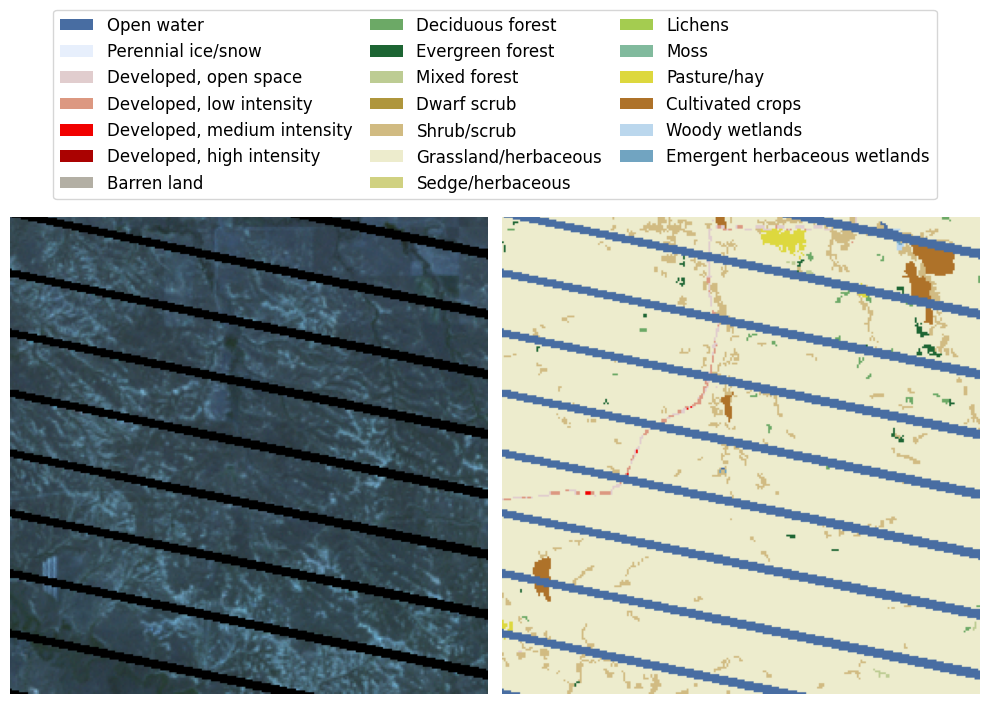

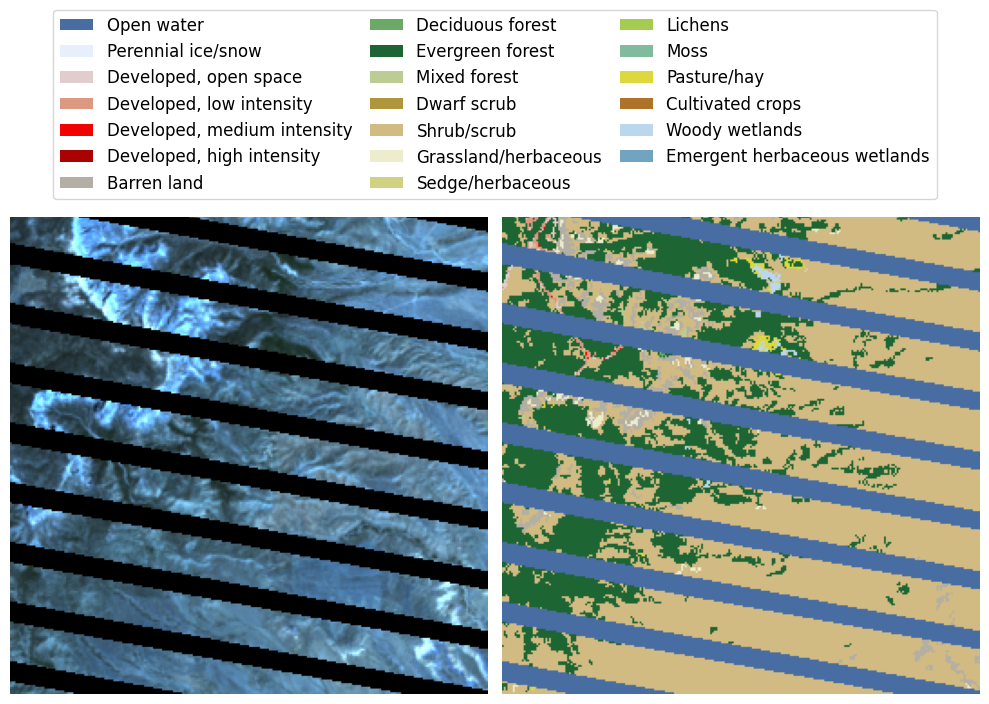

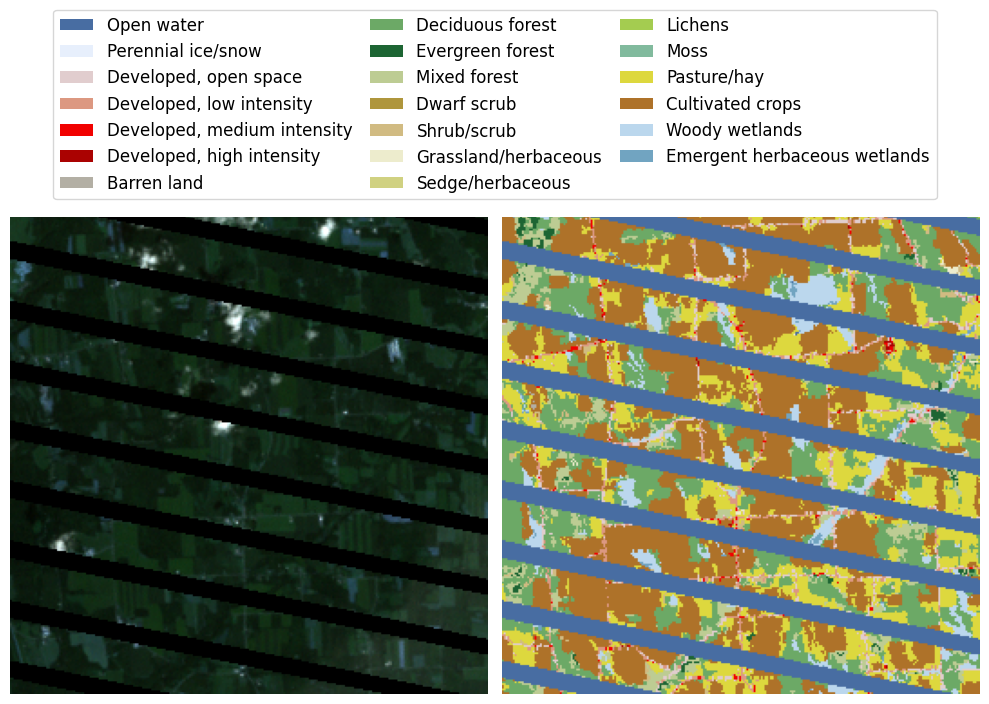

In [ ]:
dataset_config = {
    "data_dir": "./data/ssl4eo/etm"
}
dataset = SSL4EODataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(350);
dataset.show_image(1500);

In [5]:
dataset.data_distribution_table()

,Number of pixels
Open water,409344352.0
Perennial ice/snow,124454.0
"Developed, open space",36523336.0
"Developed, low intensity",23090842.0
"Developed, medium intensity",13593578.0
"Developed, high intensity",4785404.0
Barren land,14073594.0
Deciduous forest,124991200.0
Evergreen forest,162880160.0
Mixed forest,46756456.0


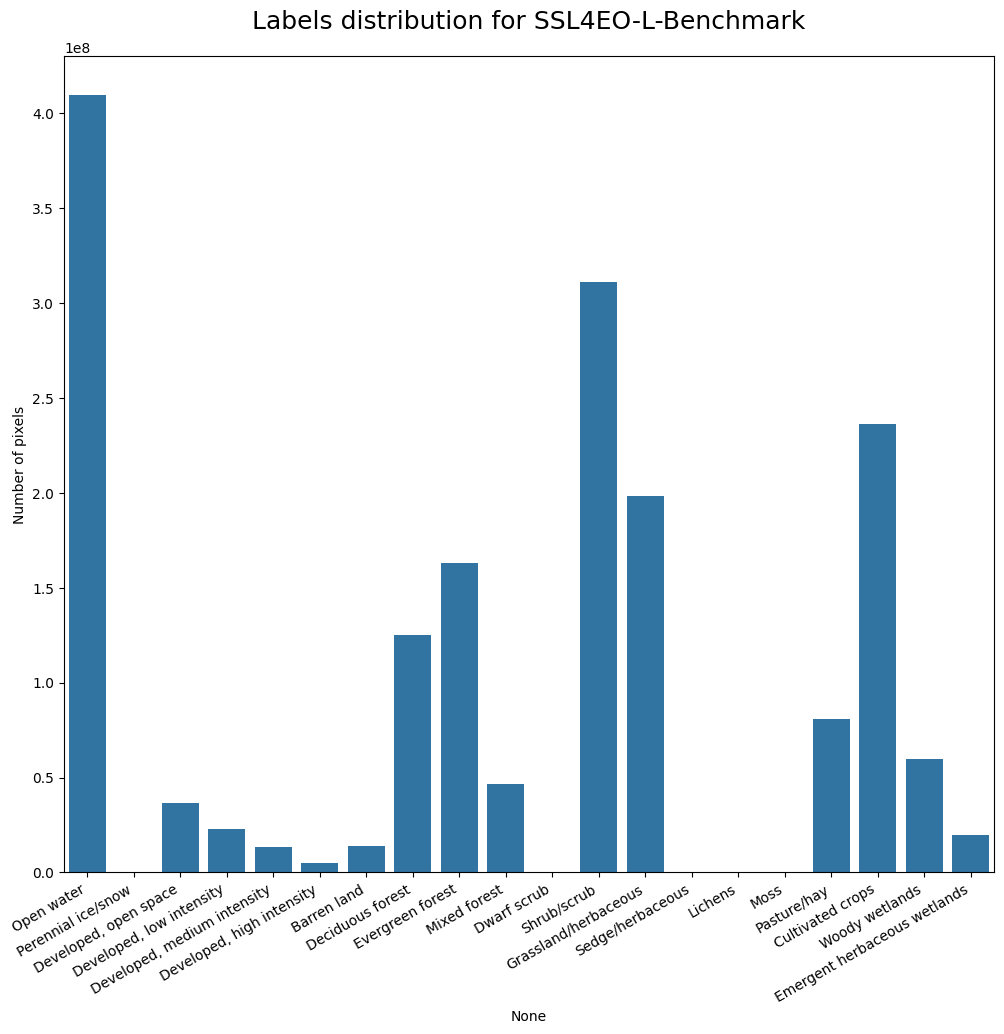

In [6]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/ssl4eo/etm",
    "csv_file": "./data/ssl4eo/etm/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = SSL4EODataset(train_dataset_config)
len(train_dataset)

20000

## Create the model

In [ ]:
epochs = 7
model_directory = "./data/ssl4eo/etm"
model_config = {
    "num_classes": 20, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-26 13:49:49,778 INFO Starting training.
training: 100%|██████████| 625/625 [2:25:25<00:00, 13.96s/it]
2025-05-26 16:15:15,572 INFO epoch: 1, time: 8726, loss:  0.64767
testing on train set: 100%|██████████| 625/625 [2:24:49<00:00, 13.90s/it]  
2025-05-26 18:40:06,863 INFO IOU:0.42982719888983856, IOU mean:0.12785203155832164, IOU per Class:[0.63464307 0.         0.         0.         0.         0.
 0.         0.29592545 0.39659062 0.         0.         0.44140169
 0.30504462 0.         0.         0.         0.         0.48343519
 0.         0.        ]
training: 100%|██████████| 625/625 [2:24:44<00:00, 13.90s/it]
2025-05-26 21:04:51,521 INFO epoch: 2, time: 8685, loss:  0.41280
testing on train set: 100%|██████████| 625/625 [2:25:02<00:00, 13.92s/it]  
2025-05-26 23:29:53,710 INFO IOU:0.47968646497496953, IOU mean:0.15029929325737407, IOU per Class:[0.68195892 0.         0.         0.         0.         0.
 0.         0.315438   0.42958933 0.         0.         0.48960294
 0.38

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/ssl4eo/etm",
    "csv_file": "./data/ssl4eo/etm/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = SSL4EODataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/ssl4eo/etm/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2500


2025-05-28 06:46:18,741 INFO Loading checkpoint /home/dragik/data/FAIR_EO/ssl4eo/etm/checkpoint.pth.tar
2025-05-28 06:46:19,200 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/ssl4eo/etm/checkpoint.pth.tar at epoch 8
testing on test set: 100%|██████████| 625/625 [18:26<00:00,  1.77s/it]


[{'IOU': 0.5079693887390443,
  'IOU mean': 0.16524057986121915,
  'IOU per Class': array([0.73674944, 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.32977925, 0.44536836, 0.        ,
         0.        , 0.54023388, 0.41153724, 0.        , 0.        ,
         0.        , 0.27107386, 0.57006956, 0.        , 0.        ])}]

## Predictions

2025-05-28 07:05:49,245 INFO Loading checkpoint /home/dragik/data/FAIR_EO/ssl4eo/etm/checkpoint.pth.tar
2025-05-28 07:05:49,680 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/ssl4eo/etm/checkpoint.pth.tar at epoch 8


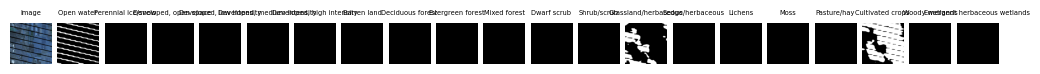

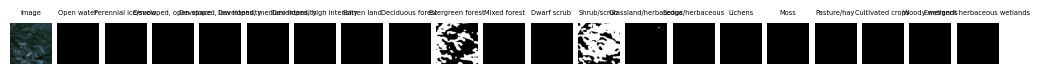

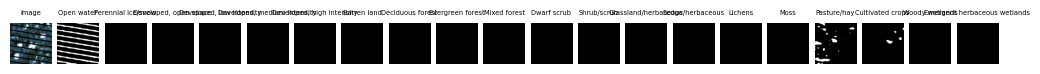

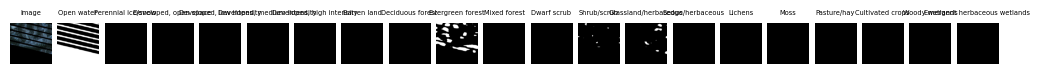

In [ ]:
model_path = "./data/ssl4eo/etm/checkpoint.pth.tar"
labels = ["Open water","Perennial ice/snow","Developed, open space","Developed, low intensity","Developed, medium intensity","Developed, high intensity","Barren land","Deciduous forest","Evergreen forest","Mixed forest","Dwarf scrub","Shrub/scrub","Grassland/herbaceous","Sedge/herbaceous","Lichens","Moss","Pasture/hay","Cultivated crops","Woody wetlands","Emergent herbaceous wetlands"]
transform = MinMaxNormTranspose()
plt.rcParams.update({'font.size': 4})
model.load_model(model_path)
csv_file = "./data/ssl4eo/etm/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/ssl4eo/etm/' + test_list[0])
image = image[:,:,0:3]
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/ssl4eo/etm/' + test_list[1])
image = image[:,:,0:3]
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/ssl4eo/etm/' + test_list[10])
image = image[:,:,0:3]
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/ssl4eo/etm/' + test_list[50])
image = image[:,:,0:3]
fig = model.predict_masks(image, labels, transform)